# 🏠 Home Price Prediction
## Machine Learning Project — Linear Regression

---

| | |
|---|---|
| **Algorithm** | Linear Regression |
| **Library** | scikit-learn |
| **Dataset** | 55 house records (CSV) |
| **Target** | Predict house price |
| **Level** | Beginner |

---

### 📌 What This Notebook Does
This notebook trains a Machine Learning model to **predict the selling price** of a house  
based on three features:
- 📐 `area` — Size of the house in square feet
- 🛏️ `bedrooms` — Number of bedrooms
- 🏚️ `house_age` — Age of the house in years

---
## ⚙️ Step 1 — Import Libraries

In [12]:
import pandas as pd
import numpy as np
import math
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from sklearn import linear_model
from sklearn.metrics import mean_absolute_error, r2_score

print('✅ All libraries imported successfully!')

✅ All libraries imported successfully!


---
## 📂 Step 2 — Load the Dataset

> **File:** `2.P.1 hourprice2.csv`  
> Make sure this CSV file is in the **same folder** as this notebook.

In [13]:
df = pd.read_csv('2.P.02 ML---Project---Home Price Prediction.csv')

print(f'Dataset Shape : {df.shape[0]} rows × {df.shape[1]} columns')
print()
df

Dataset Shape : 55 rows × 4 columns



,area,bedrooms,house_age,price
0,2200,3.0,20,440000
1,2900,4.0,15,580000
2,3500,NaN,18,700000
3,3900,3.0,30,550000
4,4300,5.0,8,920000
5,1800,2.0,25,360000
6,2100,3.0,12,430000
7,2600,4.0,10,530000
8,3100,3.0,22,610000
9,3700,4.0,5,780000


---
## 🔍 Step 3 — Explore the Data (EDA)

Check for **missing values**, **data types**, and basic **statistics**.

In [14]:
print('─── Data Types ───────────────────')
print(df.dtypes)
print()
print('─── Missing Values ───────────────')
print(df.isnull().sum())

─── Data Types ───────────────────
area           int64
bedrooms     float64
house_age      int64
price          int64
dtype: object

─── Missing Values ───────────────
area         0
bedrooms     1
house_age    0
price        0
dtype: int64


In [15]:
print('─── Basic Statistics ─────────────')
df.describe()

─── Basic Statistics ─────────────


,area,bedrooms,house_age,price
count,55.000000,54.000000,55.000000,55.000000
mean,2836.363636,3.333333,17.036364,569345.454545
std,784.777307,0.911147,10.150650,168650.330586
min,1500.000000,2.000000,1.000000,290000.000000
25%,2250.000000,3.000000,8.500000,450000.000000
50%,2800.000000,3.000000,16.000000,565000.000000
75%,3425.000000,4.000000,24.500000,652500.000000
max,4300.000000,5.000000,40.000000,920000.000000


---
## 🧹 Step 4 — Handle Missing Values

The `bedrooms` column has **1 missing value (NaN)**.  
We fill it using the **median** — because median is not affected by outliers.

| Method | Formula | Sensitive to Outliers? |
|--------|---------|------------------------|
| Mean | Sum ÷ Count | ✅ Yes |
| **Median** | **Middle value** | **❌ No ← We use this** |

In [16]:
median_bedrooms = math.floor(df.bedrooms.median())
print(f'Median bedrooms (fill value): {median_bedrooms}')

df.bedrooms = df.bedrooms.fillna(median_bedrooms)

print(f'Missing values after fix: {df.isnull().sum().sum()}')
print()
df.head()

Median bedrooms (fill value): 3
Missing values after fix: 0



,area,bedrooms,house_age,price
0,2200,3.0,20,440000
1,2900,4.0,15,580000
2,3500,3.0,18,700000
3,3900,3.0,30,550000
4,4300,5.0,8,920000


---
## 🤖 Step 5 — Train the Linear Regression Model

**Features (X)** → What the model learns from:  
`area`, `bedrooms`, `house_age`

**Target (y)** → What the model predicts:  
`price`


In [17]:
# ── Define Features and Target ───────────────────────────
features = ['area', 'bedrooms', 'house_age']
X = df[features]       # Input  → 3 columns
y = df.price           # Output → price column

# ── Create and Train the Model ───────────────────────────
reg = linear_model.LinearRegression()
reg.fit(X, y)          # ✅ Model is trained here

print('✅ Model trained successfully!')
print()
print('─── Learned Formula ──────────────────────────────────')
for feature, coef in zip(features, reg.coef_):
    direction = '+' if coef >= 0 else ''
    print(f'  {direction}{coef:.2f}  ×  {feature}')
print(f'  +{reg.intercept_:.2f}  (intercept)')
print('──────────────────────────────────────────────────────')

✅ Model trained successfully!

─── Learned Formula ──────────────────────────────────
  +180.42  ×  area
  +13991.60  ×  bedrooms
  -2060.30  ×  house_age
  +46153.07  (intercept)
──────────────────────────────────────────────────────


---
## 📊 Step 6 — Evaluate the Model

| Metric | Meaning | Our Score |
|--------|---------|----------|
| **R² Score** | Closer to 1.0 = better fit | 0.97 ✅ |
| **MAE** | Average ₨ error per prediction | ₨18,154 ✅ |

In [18]:
y_pred = reg.predict(X)

r2  = r2_score(y, y_pred)
mae = mean_absolute_error(y, y_pred)

print('─── Model Evaluation ─────────────────────────')
print(f'  R² Score            : {r2:.4f}  (max = 1.0)')
print(f'  Mean Absolute Error : ₨ {mae:,.0f}')
print('──────────────────────────────────────────────')

if r2 >= 0.90:
    print('  🟢 Excellent model accuracy!')
elif r2 >= 0.70:
    print('  🟡 Good model accuracy.')
else:
    print('  🔴 Model needs improvement.')

─── Model Evaluation ─────────────────────────
  R² Score            : 0.9686  (max = 1.0)
  Mean Absolute Error : ₨ 18,154
──────────────────────────────────────────────
  🟢 Excellent model accuracy!


---
## 🔮 Step 7 — Predict House Prices

Give the model a new house → it returns the predicted price.

```
reg.predict([[area, bedrooms, house_age]])
```

In [19]:
# Original predictions from your notebook
p1 = reg.predict(pd.DataFrame([[3200, 5, 30]], columns=features))[0]
p2 = reg.predict(pd.DataFrame([[2100, 3,  7]], columns=features))[0]
p3 = reg.predict(pd.DataFrame([[2500, 4, 12]], columns=features))[0]

print('─── Predictions ───────────────────────────────────────────')
print(f'  House A → area=3200, bedrooms=5, age=30 yrs : ₨ {p1:>10,.0f}')
print(f'  House B → area=2100, bedrooms=3, age= 7 yrs : ₨ {p2:>10,.0f}')
print(f'  House C → area=2500, bedrooms=4, age=12 yrs : ₨ {p3:>10,.0f}')
print('───────────────────────────────────────────────────────────')

─── Predictions ───────────────────────────────────────────
  House A → area=3200, bedrooms=5, age=30 yrs : ₨    631,648
  House B → area=2100, bedrooms=3, age= 7 yrs : ₨    452,589
  House C → area=2500, bedrooms=4, age=12 yrs : ₨    528,447
───────────────────────────────────────────────────────────


In [20]:
# ── Try Your Own House ────────────────────────────────────
my_area      = 3000   # ← change this
my_bedrooms  = 4      # ← change this
my_house_age = 10     # ← change this

my_price = reg.predict(
    pd.DataFrame([[my_area, my_bedrooms, my_house_age]], columns=features)
)[0]

print(f'Your House ({my_area} sqft | {my_bedrooms} bed | {my_house_age} yrs old)')
print(f'Predicted Price → ₨ {my_price:,.0f}')

Your House (3000 sqft | 4 bed | 10 yrs old)
Predicted Price → ₨ 622,778


---
## 📈 Step 8 — Graphs & Visualizations

Six charts are generated:

| # | Graph | Purpose |
|---|-------|---------|
| 1 | Area vs Price | Shows regression trend |
| 2 | Actual vs Predicted | Shows model accuracy |
| 3 | Avg Price by Bedrooms | Bar chart comparison |
| 4 | House Age vs Price | Color-coded scatter |
| 5 | Price Distribution | Histogram |
| 6 | ML Flowchart | Project pipeline |

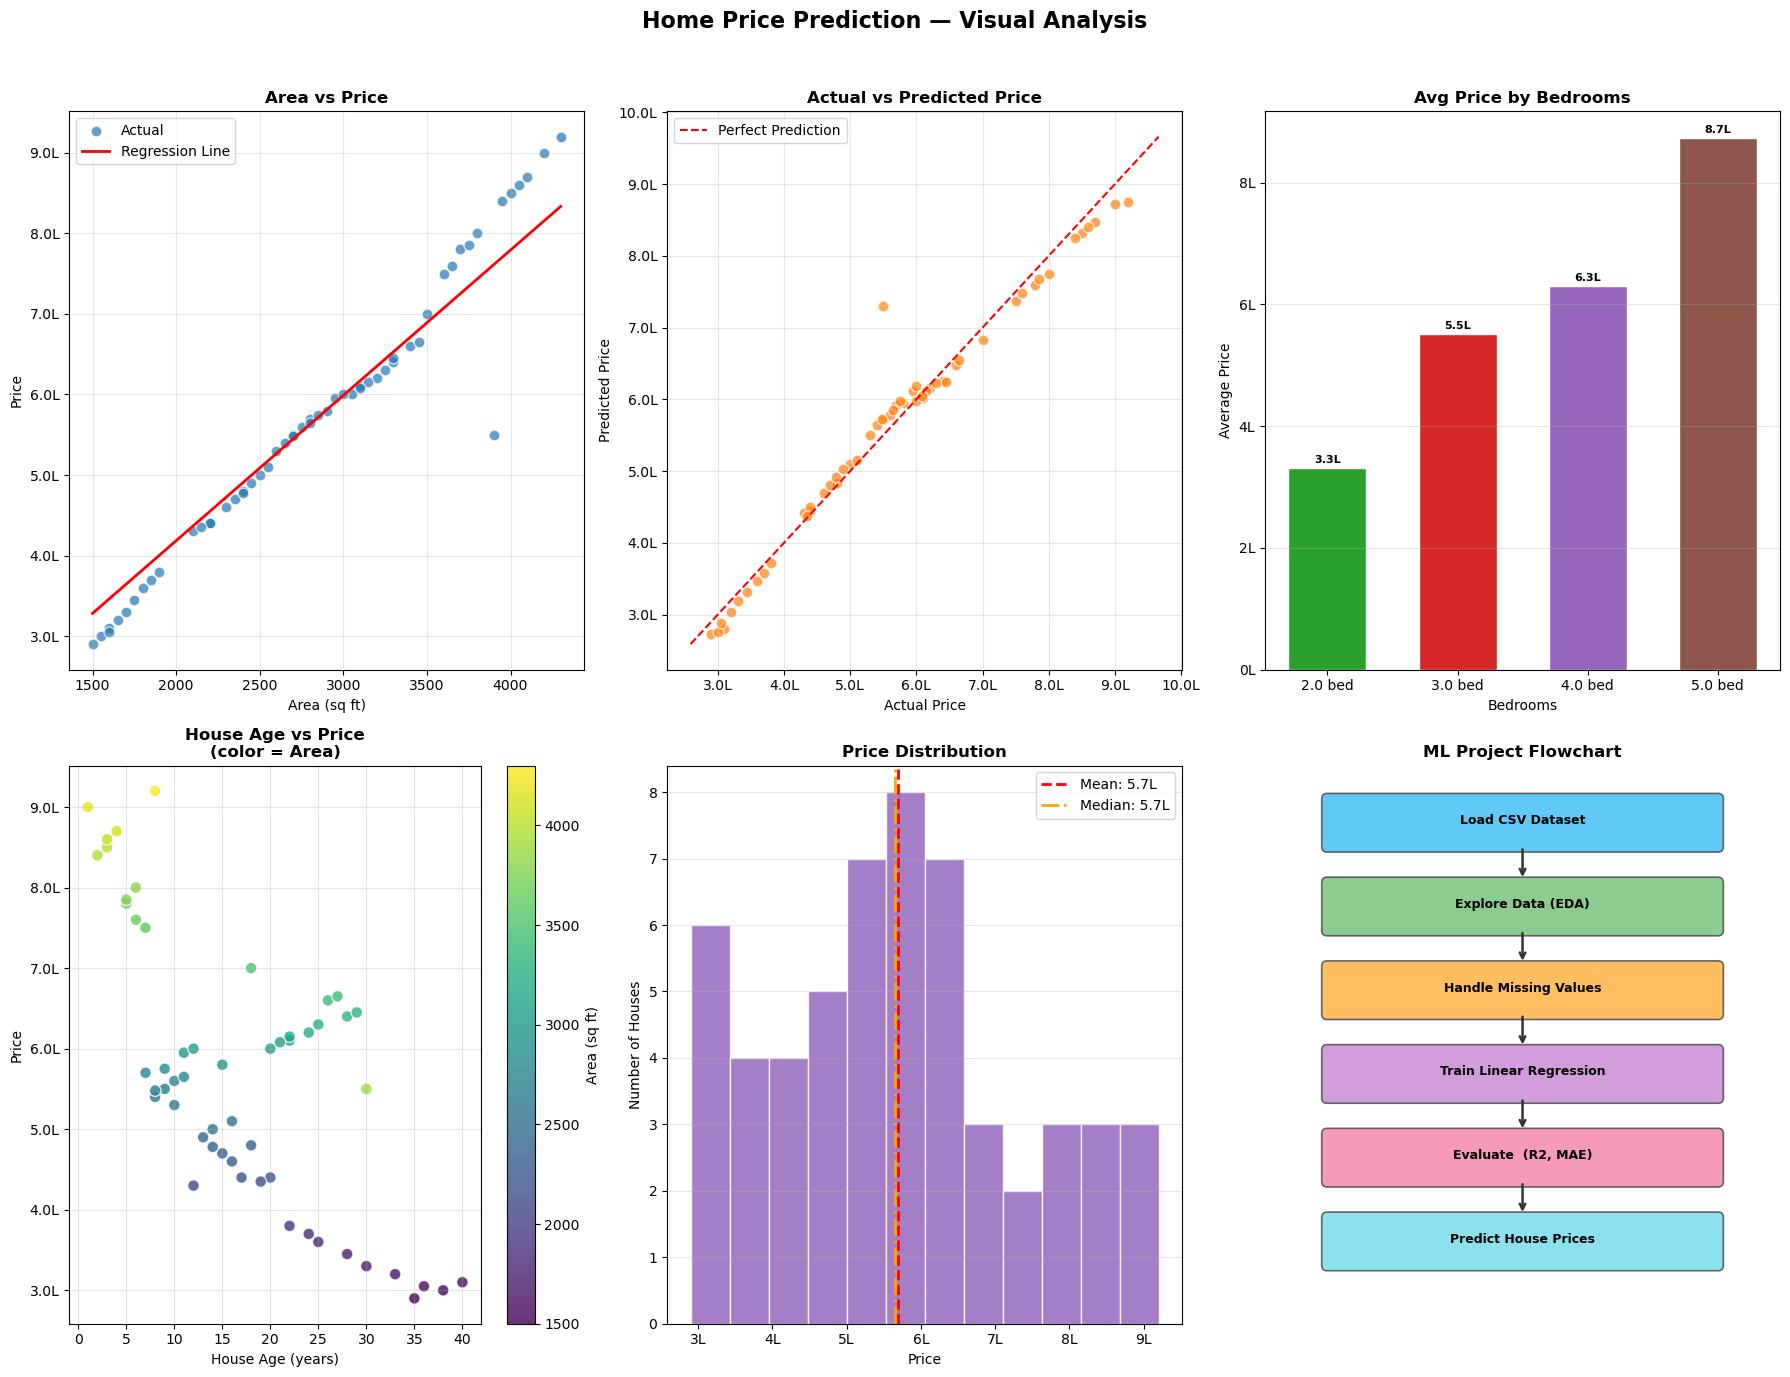

Graphs saved as: 2.P.02 home_price_prediction_graphs.png


In [21]:
%matplotlib inline

fig = plt.figure(figsize=(18, 14))
fig.suptitle('Home Price Prediction — Visual Analysis',
             fontsize=16, fontweight='bold', y=0.98)

colors = plt.cm.tab10.colors

# ── Graph 1: Area vs Price ────────────────────────────────
ax1 = fig.add_subplot(2, 3, 1)
ax1.scatter(df.area, df.price, color=colors[0], alpha=0.7,
            edgecolors='white', s=60, label='Actual')
x_line = np.linspace(df.area.min(), df.area.max(), 100)
pred_line = reg.predict(
    pd.DataFrame(
        np.column_stack([x_line,
                         np.full(100, df.bedrooms.mean()),
                         np.full(100, df.house_age.mean())]),
        columns=features
    )
)
ax1.plot(x_line, pred_line, color='red', linewidth=2, label='Regression Line')
ax1.set_title('Area vs Price', fontweight='bold')
ax1.set_xlabel('Area (sq ft)')
ax1.set_ylabel('Price')
ax1.legend()
ax1.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f'{v/1e5:.1f}L'))
ax1.grid(True, alpha=0.3)

# ── Graph 2: Actual vs Predicted ──────────────────────────
ax2 = fig.add_subplot(2, 3, 2)
ax2.scatter(y, y_pred, color=colors[1], alpha=0.7,
            edgecolors='white', s=60)
lims = [min(y.min(), y_pred.min())*0.95, max(y.max(), y_pred.max())*1.05]
ax2.plot(lims, lims, 'r--', linewidth=1.5, label='Perfect Prediction')
ax2.set_title('Actual vs Predicted Price', fontweight='bold')
ax2.set_xlabel('Actual Price')
ax2.set_ylabel('Predicted Price')
ax2.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f'{v/1e5:.1f}L'))
ax2.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f'{v/1e5:.1f}L'))
ax2.legend()
ax2.grid(True, alpha=0.3)

# ── Graph 3: Avg Price by Bedrooms ────────────────────────
ax3 = fig.add_subplot(2, 3, 3)
avg_price = df.groupby('bedrooms')['price'].mean()
bars = ax3.bar(avg_price.index.astype(str) + ' bed',
               avg_price.values,
               color=colors[2:2+len(avg_price)],
               edgecolor='white', width=0.6)
for bar, val in zip(bars, avg_price.values):
    ax3.text(bar.get_x() + bar.get_width()/2,
             val + 5000, f'{val/1e5:.1f}L',
             ha='center', va='bottom', fontsize=8, fontweight='bold')
ax3.set_title('Avg Price by Bedrooms', fontweight='bold')
ax3.set_xlabel('Bedrooms')
ax3.set_ylabel('Average Price')
ax3.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f'{v/1e5:.0f}L'))
ax3.grid(True, alpha=0.3, axis='y')

# ── Graph 4: House Age vs Price ───────────────────────────
ax4 = fig.add_subplot(2, 3, 4)
scatter = ax4.scatter(df.house_age, df.price,
                      c=df.area, cmap='viridis',
                      alpha=0.8, s=70, edgecolors='white')
plt.colorbar(scatter, ax=ax4, label='Area (sq ft)')
ax4.set_title('House Age vs Price\n(color = Area)', fontweight='bold')
ax4.set_xlabel('House Age (years)')
ax4.set_ylabel('Price')
ax4.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f'{v/1e5:.1f}L'))
ax4.grid(True, alpha=0.3)

# ── Graph 5: Price Distribution ───────────────────────────
ax5 = fig.add_subplot(2, 3, 5)
ax5.hist(df.price, bins=12, color=colors[4],
         edgecolor='white', alpha=0.85)
ax5.axvline(df.price.mean(), color='red', linestyle='--',
            linewidth=2, label=f"Mean: {df.price.mean()/1e5:.1f}L")
ax5.axvline(df.price.median(), color='orange', linestyle='-.',
            linewidth=2, label=f"Median: {df.price.median()/1e5:.1f}L")
ax5.set_title('Price Distribution', fontweight='bold')
ax5.set_xlabel('Price')
ax5.set_ylabel('Number of Houses')
ax5.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f'{v/1e5:.0f}L'))
ax5.legend()
ax5.grid(True, alpha=0.3, axis='y')

# ── Graph 6: ML Project Flowchart ────────────────────────
ax6 = fig.add_subplot(2, 3, 6)
ax6.set_xlim(0, 10)
ax6.set_ylim(0, 10)
ax6.axis('off')
ax6.set_title('ML Project Flowchart', fontweight='bold')
steps = [
    (5, 9.0, 'Load CSV Dataset',          '#4FC3F7'),
    (5, 7.5, 'Explore Data (EDA)',         '#81C784'),
    (5, 6.0, 'Handle Missing Values',      '#FFB74D'),
    (5, 4.5, 'Train Linear Regression',    '#CE93D8'),
    (5, 3.0, 'Evaluate  (R2, MAE)',        '#F48FB1'),
    (5, 1.5, 'Predict House Prices',       '#80DEEA'),
]
for x, yp, label, color in steps:
    ax6.add_patch(
        mpatches.FancyBboxPatch((x-3.8, yp-0.45), 7.6, 0.85,
                                boxstyle='round,pad=0.1',
                                facecolor=color, edgecolor='#555',
                                linewidth=1.2, alpha=0.9))
    ax6.text(x, yp+0.01, label, ha='center', va='center',
             fontsize=9, fontweight='bold')
for i in range(len(steps)-1):
    _, y_top, _, _ = steps[i]
    _, y_bot, _, _ = steps[i+1]
    ax6.annotate('', xy=(5, y_bot+0.45), xytext=(5, y_top-0.45),
                 arrowprops=dict(arrowstyle='->', color='#333', lw=1.8))

plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.savefig('2.P.02 home_price_prediction_graphs.png', dpi=150, bbox_inches='tight')
plt.show()
print('Graphs saved as: 2.P.02 home_price_prediction_graphs.png')

---
## ✅ Step 9 — Final Summary

In [22]:
print('=' * 55)
print('  HOME PRICE PREDICTION — FINAL SUMMARY')
print('=' * 55)
print(f'  Dataset Rows        : {len(df)}')
print(f'  Features Used       : {features}')
print(f'  R2 Score            : {r2:.4f}')
print(f'  Mean Absolute Error : Rs. {mae:,.0f}')
print()
print('  Learned Coefficients:')
for f, c in zip(features, reg.coef_):
    print(f'    {f:<12} → {c:+.2f}')
print(f'    intercept    → {reg.intercept_:.2f}')
print()
print('  Sample Predictions:')
print(f'    3200sqft, 5bed, 30yrs → Rs. {p1:,.0f}')
print(f'    2100sqft, 3bed,  7yrs → Rs. {p2:,.0f}')
print(f'    2500sqft, 4bed, 12yrs → Rs. {p3:,.0f}')
print('=' * 55)
print('  PROJECT COMPLETE!')
print('=' * 55)

  HOME PRICE PREDICTION — FINAL SUMMARY
  Dataset Rows        : 55
  Features Used       : ['area', 'bedrooms', 'house_age']
  R2 Score            : 0.9686
  Mean Absolute Error : Rs. 18,154

  Learned Coefficients:
    area         → +180.42
    bedrooms     → +13991.60
    house_age    → -2060.30
    intercept    → 46153.07

  Sample Predictions:
    3200sqft, 5bed, 30yrs → Rs. 631,648
    2100sqft, 3bed,  7yrs → Rs. 452,589
    2500sqft, 4bed, 12yrs → Rs. 528,447
  PROJECT COMPLETE!


---

## 📁 Project Files

```
your_project_folder/
│
├── Home_Price_Prediction.ipynb        ← This notebook
├── 2.P.1 hourprice2.csv               ← Dataset (55 rows)
├── home_price_prediction_graphs.png   ← Generated graphs
├── README.md                          ← Project overview
└── PROJECT_DESCRIPTION.txt            ← Detailed explanation
```

---
*Built with Python 3 | pandas | numpy | scikit-learn | matplotlib*